In [12]:
import numpy as np 
import pandas as pd 
from scipy.stats import chi2
from pandas.io.stata import StataReader

In [23]:
# Load the Stata dataset, extract variable labels, and drop missing survey design or outcome records.
import pandas as pd
import numpy as np
from pandas.io.stata import StataReader

data = pd.read_stata("MICS-child-ISRC.dta", convert_categoricals=False)
stata_file = StataReader("MICS-child-ISRC.dta")
variable_labels = stata_file.variable_labels()

survey_cols = ['hh1', 'chweight', 'strata', 'severe_wasting']
df_clean = data.dropna(subset=survey_cols).copy()
df_clean = df_clean[df_clean['chweight'] > 0].reset_index(drop=True)

In [25]:
# Fit a survey-weighted GLM with cluster-robust standard errors on core child, maternal, and household predictors.
import statsmodels.api as sm
import statsmodels.formula.api as smf

features = [
    'ub2', 'female', 'diarrhoea_2w', 'cough_2w', 'breathing_2w',
    'dds', 'edu_level', 'mage_cat', 'parity_cat', 'water_cat',
    'toilet_cat', 'fuel_cat', 'urban', 'wealth', 'division'
]

df_model = df_clean.dropna(subset=features).copy()
formula = "severe_wasting ~ ub2 + female + diarrhoea_2w + cough_2w + breathing_2w + dds + C(edu_level) + C(mage_cat) + C(parity_cat) + C(water_cat) + C(toilet_cat) + C(fuel_cat) + urban + C(wealth) + C(division)"

glm_model = smf.glm(
    formula=formula,
    data=df_model,
    family=sm.families.Binomial(),
    freq_weights=df_model['chweight']
)
glm_results = glm_model.fit(cov_type='cluster', cov_kwds={'groups': df_model['hh1']})
print(glm_results.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:         severe_wasting   No. Observations:                 8770
Model:                            GLM   Df Residuals:                  8789.31
Model Family:                Binomial   Df Model:                           41
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -1243.6
Date:                Wed, 21 Oct 2026   Deviance:                       2487.3
Time:                        21:17:44   Pearson chi2:                 8.75e+03
No. Iterations:                    21   Pseudo R-squ. (CS):           0.008781
Covariance Type:              cluster                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              -22.0509 

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\statsmodels\genmod\generalized_linear_model.py:1488: SpecificationWarning: cov_type not fully supported with freq_weights
  glm_results = GLMResults(


In [26]:
# Train a survey-weighted Random Forest classifier evaluated via cluster-grouped cross-validation on PSU (hh1).
from sklearn.model_selection import GroupKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score

X = pd.get_dummies(df_model[features], drop_first=True)
y = df_model['severe_wasting'].astype(int).to_numpy()
weights = df_model['chweight'].to_numpy()
clusters = df_model['hh1'].to_numpy()

gkf = GroupKFold(n_splits=5)
auc_scores = []

for train_idx, test_idx in gkf.split(X, y, groups=clusters):
    clf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
    clf.fit(X.iloc[train_idx], y[train_idx], sample_weight=weights[train_idx])
    preds = clf.predict_proba(X.iloc[test_idx])[:, 1]
    auc_scores.append(roc_auc_score(y[test_idx], preds, sample_weight=weights[test_idx]))

print(f"Weighted CV ROC-AUC: {np.mean(auc_scores):.4f}")

Weighted CV ROC-AUC: 0.5360


In [27]:
import shap

explainer = shap.TreeExplainer(clf)
shap_values = explainer.shap_values(X)

C:\Users\moham\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


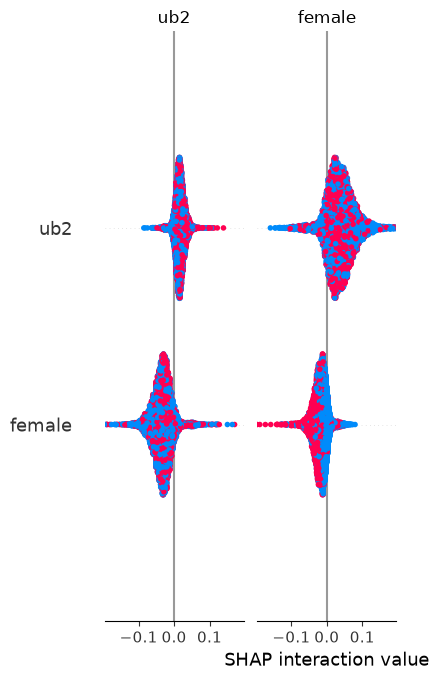

In [28]:
shap.summary_plot(shap_values[1] if isinstance(shap_values, list) else shap_values, X)